1 · La pregunta

• ¿Qué quiero predecir? 

Quiero predecir el tiempo total en minutos que tardará un pedido en ser entregado al cliente (la variable tiempo_real_min).

• ¿En qué momento se haría esa predicción? 

La predicción se realizaría en el instante exacto en que el cliente confirma y paga su pedido en la aplicación, antes de que comience la preparación en el restaurante o la asignación definitiva de la ruta.

• ¿Es un problema de regresión o de clasificación? 

Es un problema de regresión, ya que el objetivo (tiempo_real_min) es una variable numérica continua expresada en minutos.

# Exploración del dataset de delivery

Este notebook revisa la calidad y los rangos del dataset `delivery_50000.csv` y visualiza la distribución de `tiempo_real_min`.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

candidatos = [Path("data/raw/delivery_50000.csv"), Path("../data/raw/delivery_50000.csv")]
data_path = next((ruta for ruta in candidatos if ruta.exists()), None)
if data_path is None:
    raise FileNotFoundError("No se encontró data/raw/delivery_50000.csv")

delivery = pd.read_csv(data_path)
print(f"Archivo cargado: {data_path}")
print(f"Filas: {delivery.shape[0]:,}")
print(f"Columnas: {delivery.shape[1]:,}")

Archivo cargado: ../data/raw/delivery_50000.csv
Filas: 50,180
Columnas: 23


## Valores nulos, duplicados e identificadores repetidos

In [2]:
nulos_por_columna = delivery.isna().sum().rename("valores_nulos").to_frame()
print("Valores nulos por columna:")
display(nulos_por_columna)

print(f"Filas duplicadas completas: {delivery.duplicated().sum():,}")
print(f"Valores de id_pedido repetidos: {delivery["id_pedido"].duplicated().sum():,}")
print(f"id_pedido distintos con repetición: {delivery.loc[delivery["id_pedido"].duplicated(keep=False), "id_pedido"].nunique():,}")

Valores nulos por columna:


,valores_nulos
id_pedido,0
fecha_hora,0
zona,0
restaurante_id,0
tipo_comida,0
distancia_km,0
cantidad_items,0
importe,0
metodo_pago,0
cliente_nuevo,0


Filas duplicadas completas: 179
Valores de id_pedido repetidos: 180
id_pedido distintos con repetición: 180


## Valores únicos de las columnas de texto

Se muestran los valores únicos para detectar erratas y diferencias de mayúsculas/minúsculas.

In [3]:
columnas_categoricas = ["zona", "tipo_comida", "metodo_pago", "clima", "vehiculo"]
for col in columnas_categoricas:
    print(col, sorted(delivery[col].dropna().unique()))

zona ['Afueras', 'Centro', 'Este', 'Norte', 'Oeste', 'Puerto', 'Sur', 'Universidad']
tipo_comida ['CHINA', 'HAMBURGUESAS', 'MEXICANA', 'PARRILLA', 'PIZZA', 'POSTRES', 'SALUDABLE', 'SUSHI', 'china', 'hamburguesas', 'mexicana', 'parrilla', 'pizza', 'postres', 'saludable', 'sushi']
metodo_pago ['app', 'efectivo', 'tarjeta']
clima ['despejado', 'lluvia', 'nublado', 'tormenta']
vehiculo ['auto', 'bici', 'moto']


## Mínimos y máximos de columnas numéricas

Estos rangos permiten localizar valores imposibles o fuera de dominio.

In [4]:
columnas_numericas = delivery.select_dtypes(include="number").columns
tabla_min_max = delivery[columnas_numericas].agg(["min", "max"]).T
tabla_min_max.columns = ["min", "max"]
display(tabla_min_max)

,min,max
id_pedido,1.00,50000.00
distancia_km,-6.41,18.00
cantidad_items,1.00,10.00
importe,0.00,167.51
cliente_nuevo,0.00,1.00
pedidos_previos,0.00,153.00
temperatura,-8.70,43.60
repartidores_disponibles,1.00,39.00
pedidos_activos_zona,0.00,70.00
tiempo_preparacion_estimado,8.00,35.00


## Distribución de `tiempo_real_min`

Media de tiempo_real_min: 36.42 min
Mediana de tiempo_real_min: 34.70 min


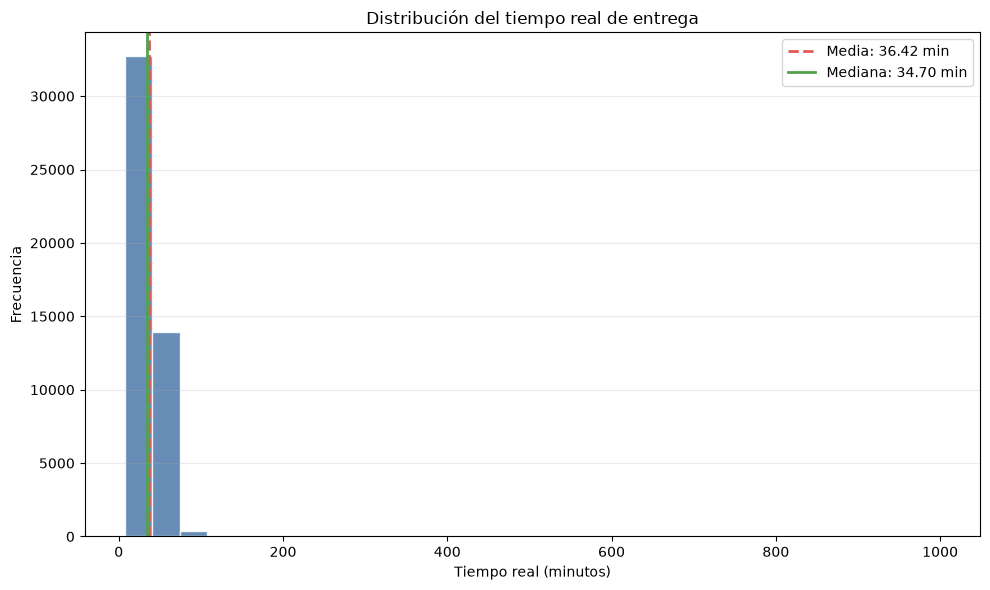

In [5]:
media_tiempo = delivery["tiempo_real_min"].mean()
mediana_tiempo = delivery["tiempo_real_min"].median()

fig, ax = plt.subplots(figsize=(10, 6))
ax.hist(delivery["tiempo_real_min"], bins=30, color="#4C78A8", edgecolor="white", alpha=0.85)
ax.axvline(media_tiempo, color="#E45756", linestyle="--", linewidth=2, label=f"Media: {media_tiempo:,.2f} min")
ax.axvline(mediana_tiempo, color="#54A24B", linestyle="-", linewidth=2, label=f"Mediana: {mediana_tiempo:,.2f} min")
ax.set_title("Distribución del tiempo real de entrega")
ax.set_xlabel("Tiempo real (minutos)")
ax.set_ylabel("Frecuencia")
ax.legend()
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
print(f"Media de tiempo_real_min: {media_tiempo:,.2f} min")
print(f"Mediana de tiempo_real_min: {mediana_tiempo:,.2f} min")
plt.show()

## 2 · Conocer los datos

La revisión de calidad del dataset muestra los siguientes problemas que deben tratarse antes de modelar:

- **Valores nulos:** `temperatura` tiene 600 nulos, `repartidores_disponibles` 301, `tiempo_real_min` 3.130, `llego_tarde` 3.130 y `calificacion` 19.482. El resto de columnas no tiene nulos.
- **Duplicados e identificadores:** hay 179 filas completamente duplicadas. Además, hay **180 valores de `id_pedido` repetidos** (180 pedidos distintos aparecen más de una vez), por lo que `id_pedido` no debe asumirse único sin investigar el origen de esas repeticiones.
- **Erratas y categorías inconsistentes:** `tipo_comida` mezcla exactamente ocho categorías en mayúsculas con sus equivalentes en minúsculas: `CHINA`/`china`, `HAMBURGUESAS`/`hamburguesas`, `MEXICANA`/`mexicana`, `PARRILLA`/`parrilla`, `PIZZA`/`pizza`, `POSTRES`/`postres`, `SALUDABLE`/`saludable` y `SUSHI`/`sushi`. No se detectaron espacios sobrantes en las categorías mostradas. `zona` no presenta erratas de mayúsculas/minúsculas ni categorías duplicadas por formato: `Afueras`, `Centro`, `Este`, `Norte`, `Oeste`, `Puerto`, `Sur` y `Universidad`.
- **Valores numéricos imposibles o sospechosos:** `distancia_km` tiene un mínimo de **-6,41 km**, imposible como distancia, y debe revisarse o corregirse. `importe` llega a **0,00**, sospechoso para un pedido, aunque podría representar un caso excepcional. `tiempo_real_min` alcanza **999 minutos**, un extremo claramente anómalo para un delivery y probablemente un código de error o dato corrupto. La temperatura mínima de **-8,70 °C** no es imposible por sí misma. Los ceros de `pedidos_previos`, `pedidos_activos_zona`, `propina` y las variables binarias (`cliente_nuevo`, `llego_tarde`, `cancelado`) son valores válidos por su significado y no se marcan como imposibles.

En resumen, antes de continuar conviene imputar o analizar los nulos, resolver los duplicados de pedidos, normalizar `tipo_comida` (por ejemplo, pasando todo a minúsculas), investigar los valores negativos de `distancia_km`, los importes cero y el extremo de 999 minutos, y decidir cómo tratar las filas duplicadas.

In [6]:
def limpiar_datos(df):
    """Aplica las reglas de limpieza y muestra las filas restantes por paso."""
    limpio = df.copy()
    print(f"Filas iniciales: {len(limpio):,}")

    limpio = limpio[
        (limpio["cancelado"] == 0)
        & limpio["tiempo_real_min"].notna()
        & (limpio["tiempo_real_min"] < 999)
        & (limpio["tiempo_real_min"] > 0)
    ].copy()
    print(f"Tras eliminar cancelados y objetivos inválidos: {len(limpio):,}")

    limpio = limpio.drop_duplicates(subset=["id_pedido"], keep="first").copy()
    print(f"Tras eliminar duplicados de id_pedido: {len(limpio):,}")

    columnas_texto = ["tipo_comida", "zona", "metodo_pago", "clima", "vehiculo"]
    for columna in columnas_texto:
        limpio[columna] = limpio[columna].str.strip().str.lower()
    print(f"Tras normalizar categorías: {len(limpio):,}")

    limpio = limpio[(limpio["distancia_km"] > 0) & (limpio["importe"] > 0)].copy()
    print(f"Tras eliminar distancia_km <= 0 e importe <= 0: {len(limpio):,}")

    for columna in ["temperatura", "repartidores_disponibles"]:
        limpio[columna] = limpio[columna].fillna(limpio[columna].median())
    print(f"Tras imputar nulos con la mediana: {len(limpio):,}")
    return limpio

delivery_limpio = limpiar_datos(delivery)

Filas iniciales: 50,180
Tras eliminar cancelados y objetivos inválidos: 47,043
Tras eliminar duplicados de id_pedido: 46,875


Tras normalizar categorías: 46,875
Tras eliminar distancia_km <= 0 e importe <= 0: 46,857
Tras imputar nulos con la mediana: 46,857


## 3 · Limpiar los datos

La función `limpiar_datos(df)` aplica las reglas de limpieza en un orden explícito y devuelve una copia del DataFrame, sin modificar el original. El seguimiento de filas es:

| Paso | Filas restantes |
|---|---:|
| Dataset inicial | 50.180 |
| Tras eliminar cancelados y objetivos inválidos | 47.043 |
| Tras eliminar duplicados de `id_pedido` | 46.875 |
| Tras normalizar categorías | 46.875 |
| Tras eliminar `distancia_km <= 0` e `importe <= 0` | 46.857 |
| Tras imputar nulos con la mediana | 46.857 |

1. **Pedidos no entregados u objetivo inválido:** se conservan únicamente los pedidos con `cancelado == 0` y un `tiempo_real_min` válido: no nulo, mayor que 0 y menor que 999. Se excluyen así los cancelados, los valores ausentes y los valores usados como código de error o imposibles. Quedan **47.043 filas**.
2. **Duplicados:** se conserva la primera aparición de cada `id_pedido` mediante `drop_duplicates(subset=["id_pedido"], keep="first")`. Quedan **46.875 filas**.
3. **Categorías:** `tipo_comida`, `zona`, `metodo_pago`, `clima` y `vehiculo` se normalizan eliminando espacios laterales y convirtiendo el texto a minúsculas. Esta transformación no cambia el número de filas: quedan **46.875**.
4. **Valores imposibles e imputación:** se eliminan las filas con `distancia_km <= 0` o `importe <= 0`, quedando **46.857 filas**. Los nulos de `temperatura` y `repartidores_disponibles` se imputan con la mediana calculada sobre los datos disponibles después de los filtros; la imputación no elimina filas.

El resultado final `delivery_limpio` contiene **46.857 filas** listas para el análisis posterior.

## Ingeniería básica de fecha

In [7]:
delivery_limpio = delivery_limpio.copy()
delivery_limpio["fecha_hora"] = pd.to_datetime(delivery_limpio["fecha_hora"])
delivery_limpio["hora"] = delivery_limpio["fecha_hora"].dt.hour
delivery_limpio["dia_semana"] = delivery_limpio["fecha_hora"].dt.day_of_week
print("Columnas de fecha creadas: hora (0-23) y dia_semana (0-6)")
print(delivery_limpio[["fecha_hora", "hora", "dia_semana"]].head())

Columnas de fecha creadas: hora (0-23) y dia_semana (0-6)
           fecha_hora  hora  dia_semana
0 2024-01-01 04:42:00     4           0
1 2024-01-01 07:27:00     7           0
2 2024-01-01 08:09:00     8           0
3 2024-01-01 08:14:00     8           0
4 2024-01-01 08:45:00     8           0


## 4 · Elegir las columnas

Para predecir el tiempo real justo cuando se confirma el pedido, `X` contiene únicamente la información disponible en ese momento: zona, tipo de comida, distancia, cantidad, importe, método de pago, características del cliente, clima, disponibilidad operativa, vehículo, tiempos estimados y las variables derivadas de la fecha (`hora` y `dia_semana`).

Se excluyen `tiempo_real_min` porque es el objetivo, y también `llego_tarde`, que se conoce después de la entrega y produciría fuga de información. `cancelado`, `propina` y `calificacion` tampoco se usan porque pueden depender del resultado posterior del pedido. Se excluyen `id_pedido`, `fecha_hora` y `restaurante_id` por ser identificadores o una representación directa de la fecha que no debe entrar sin una transformación controlada; `id_pedido` y `restaurante_id` podrían hacer que el modelo memorice entidades en lugar de aprender patrones generalizables.

In [8]:
columnas_X = [
    "zona", "tipo_comida", "distancia_km", "cantidad_items", "importe",
    "metodo_pago", "cliente_nuevo", "pedidos_previos", "clima",
    "temperatura", "repartidores_disponibles", "pedidos_activos_zona",
    "vehiculo", "tiempo_preparacion_estimado", "tiempo_prometido_min",
    "hora", "dia_semana",
]
y = delivery_limpio["tiempo_real_min"]
X = delivery_limpio[columnas_X]
print(f"X: {X.shape[0]:,} filas x {X.shape[1]} columnas")
print("y: tiempo_real_min")
print("Columnas de X:", columnas_X)

X: 46,857 filas x 17 columnas
y: tiempo_real_min
Columnas de X: ['zona', 'tipo_comida', 'distancia_km', 'cantidad_items', 'importe', 'metodo_pago', 'cliente_nuevo', 'pedidos_previos', 'clima', 'temperatura', 'repartidores_disponibles', 'pedidos_activos_zona', 'vehiculo', 'tiempo_preparacion_estimado', 'tiempo_prometido_min', 'hora', 'dia_semana']


## 5 · Separar y Línea Base

In [9]:
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

linea_base = DummyRegressor(strategy="median")
linea_base.fit(X_train, y_train)
mae_base_train = mean_absolute_error(y_train, linea_base.predict(X_train))
mae_base_test = mean_absolute_error(y_test, linea_base.predict(X_test))

print(f"Filas de entrenamiento: {len(X_train):,}")
print(f"Filas de prueba: {len(X_test):,}")
print(f"Mediana aprendida en entrenamiento: {linea_base.constant_[0, 0]:,.2f} min")
print(f"MAE línea base en entrenamiento: {mae_base_train:,.2f} min")
print(f"MAE línea base en prueba: {mae_base_test:,.2f} min")

Filas de entrenamiento: 37,485
Filas de prueba: 9,372
Mediana aprendida en entrenamiento: 34.70 min
MAE línea base en entrenamiento: 9.55 min
MAE línea base en prueba: 9.59 min


La línea base predice siempre la mediana de `tiempo_real_min` calculada únicamente en `y_train`. El MAE de prueba de esta referencia se reporta en la celda anterior y sirve como punto de comparación para los modelos posteriores.

## 6 · Comparar modelos

Se comparan cuatro modelos con sus configuraciones indicadas, usando una tubería con el mismo preprocesador y validación cruzada únicamente sobre el conjunto de entrenamiento.

In [10]:
import time

from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import KFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.tree import DecisionTreeRegressor
from xgboost import XGBRegressor

columnas_categoricas_modelo = [
    "zona", "tipo_comida", "metodo_pago", "clima", "vehiculo"
]
prep = ColumnTransformer(
    transformers=[("categoricas", OneHotEncoder(handle_unknown="ignore"), columnas_categoricas_modelo)],
    remainder="passthrough",
)

modelos_por_defecto = {
    "LinearRegression": LinearRegression(),
    "DecisionTreeRegressor": DecisionTreeRegressor(random_state=42),
    "RandomForestRegressor": RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1),
    "XGBRegressor": XGBRegressor(random_state=42, n_jobs=-1),
}
pipelines_modelos = {
    nombre: Pipeline([("prep", prep), ("model", modelo)])
    for nombre, modelo in modelos_por_defecto.items()
}

cv_modelos = KFold(n_splits=5, shuffle=True, random_state=42)
resultados_modelos_delivery = []
for nombre, pipeline in pipelines_modelos.items():
    inicio = time.perf_counter()
    validacion = cross_validate(
        pipeline, X_train, y_train, cv=cv_modelos,
        scoring="neg_mean_absolute_error", n_jobs=-1,
    )
    tiempo_seg = time.perf_counter() - inicio
    mae_folds = -validacion["test_score"]
    resultados_modelos_delivery.append({
        "modelo": nombre,
        "mae_medio": mae_folds.mean(),
        "desviacion": mae_folds.std(),
        "tiempo_seg": tiempo_seg,
    })

tabla_modelos_delivery = (
    pd.DataFrame(resultados_modelos_delivery)
    .sort_values("mae_medio")
    .reset_index(drop=True)
)
display(tabla_modelos_delivery.style.format({
    "mae_medio": "{:,.2f} min",
    "desviacion": "{:,.2f} min",
    "tiempo_seg": "{:,.2f} s",
}))
ganador_nombre = tabla_modelos_delivery.loc[0, "modelo"]
print(f"Modelo ganador por MAE medio: {ganador_nombre}")

,modelo,mae_medio,desviacion,tiempo_seg
0,XGBRegressor,4.23 min,0.04 min,2.50 s
1,RandomForestRegressor,4.39 min,0.03 min,87.47 s
2,LinearRegression,4.79 min,0.04 min,4.09 s
3,DecisionTreeRegressor,6.26 min,0.04 min,2.25 s


Modelo ganador por MAE medio: XGBRegressor


## 7 · Ajustar hiperparámetros

Se tomó el ganador de la comparación, `XGBRegressor`, y se ajustó con `RandomizedSearchCV` usando exclusivamente `X_train` e `y_train`, `n_iter=20`, `KFold(n_splits=5, shuffle=True, random_state=42)`, `scoring="neg_mean_absolute_error"`, `random_state=42` y `n_jobs=-1`. Se exploraron `n_estimators`, `max_depth`, `learning_rate`, `subsample` y `colsample_bytree`.

La mejor configuración fue `n_estimators=800`, `max_depth=4`, `learning_rate=0.05`, `subsample=0.7` y `colsample_bytree=0.7`. El MAE medio pasó de **4,23 min** en el modelo por defecto a **4,10 min** tras el ajuste, una mejora de **0,13 min**. La desviación estándar del modelo por defecto fue **0,04 min**; por tanto, la mejora **sí supera** la variabilidad entre folds. La desviación estándar del mejor resultado ajustado también fue **0,04 min**.

In [11]:
from sklearn.model_selection import RandomizedSearchCV

if ganador_nombre == "XGBRegressor":
    espacio_busqueda = {
        "model__n_estimators": [100, 200, 400, 800],
        "model__max_depth": [2, 3, 4, 6, 8],
        "model__learning_rate": [0.03, 0.05, 0.1, 0.2],
        "model__subsample": [0.7, 0.85, 1.0],
        "model__colsample_bytree": [0.7, 1.0],
    }
else:
    espacio_busqueda = {
        "model__n_estimators": [100, 200, 400, 800],
        "model__max_depth": [None, 8, 12, 16, 24],
        "model__min_samples_leaf": [1, 2, 5, 10],
        "model__max_features": [0.5, 0.75, 1.0],
    }

busqueda_ganador = RandomizedSearchCV(
    estimator=pipelines_modelos[ganador_nombre],
    param_distributions=espacio_busqueda,
    n_iter=20,
    cv=KFold(n_splits=5, shuffle=True, random_state=42),
    scoring="neg_mean_absolute_error",
    random_state=42,
    n_jobs=-1,
    return_train_score=False,
)
inicio_busqueda = time.perf_counter()
busqueda_ganador.fit(X_train, y_train)
tiempo_busqueda = time.perf_counter() - inicio_busqueda

indice_mejor = busqueda_ganador.best_index_
mae_ajustado = -busqueda_ganador.cv_results_["mean_test_score"][indice_mejor]
desviacion_ajustado = busqueda_ganador.cv_results_["std_test_score"][indice_mejor]
fila_ganador = tabla_modelos_delivery[tabla_modelos_delivery["modelo"] == ganador_nombre].iloc[0]
mae_defecto = fila_ganador["mae_medio"]
desviacion_defecto = fila_ganador["desviacion"]
mejora_mae = mae_defecto - mae_ajustado
mejora_supera_desviacion = mejora_mae > desviacion_defecto

print(f"Modelo ajustado: {ganador_nombre}")
print("Mejores hiperparámetros:", busqueda_ganador.best_params_)
print(f"Mejor MAE medio: {mae_ajustado:,.2f} min")
print(f"Desviación estándar del mejor resultado: {desviacion_ajustado:,.2f} min")
print(f"Tiempo de búsqueda: {tiempo_busqueda:,.2f} s")
print(f"MAE del modelo por defecto: {mae_defecto:,.2f} min")
print(f"Desviación estándar del modelo por defecto: {desviacion_defecto:,.2f} min")
print(f"Mejora del MAE: {mejora_mae:,.2f} min")
print(f"¿La mejora supera la desviación estándar entre folds? {mejora_supera_desviacion}")

Modelo ajustado: XGBRegressor
Mejores hiperparámetros: {'model__subsample': 0.7, 'model__n_estimators': 800, 'model__max_depth': 4, 'model__learning_rate': 0.05, 'model__colsample_bytree': 0.7}
Mejor MAE medio: 4.10 min
Desviación estándar del mejor resultado: 0.04 min
Tiempo de búsqueda: 144.58 s
MAE del modelo por defecto: 4.23 min
Desviación estándar del modelo por defecto: 0.04 min
Mejora del MAE: 0.13 min
¿La mejora supera la desviación estándar entre folds? True


La tabla de la pregunta 6 queda ordenada de menor a mayor MAE medio. En la pregunta 7, la mejora del modelo ajustado se considera claramente mayor que la variabilidad entre folds solo si la reducción del MAE supera la desviación estándar del modelo ganador por defecto.

## 8 · El examen final

El mejor estimador de `RandomizedSearchCV` se evaluó una sola vez sobre `X_test` e `y_test`. El resultado final fue:

- **MAE en prueba:** 4,1032 min
- **R² en prueba:** 0,8214
- **RMSE en prueba:** 5,2504 min

El MAE final en prueba (**4,1032 min**) es prácticamente igual al MAE medio de validación cruzada (**4,10 min**) y mejora claramente la línea base (**9,59 min**). Esto indica que el modelo generaliza de forma consistente y reduce el error de referencia en aproximadamente 5,49 minutos.

Por condiciones, el error absoluto medio más alto se observa en:

- **Clima:** lluvia, con **4,1856 min**.
- **Vehículo:** bici, con **4,1729 min**.
- **Distancia:** más de 5 km, con **4,1173 min**.

El gráfico de dispersión compara el tiempo real con el predicho; los puntos más alejados de la diagonal de predicción perfecta representan los mayores errores.

MAE en prueba: 4.1032 min
R² en prueba: 0.8214
RMSE en prueba: 5.2504 min


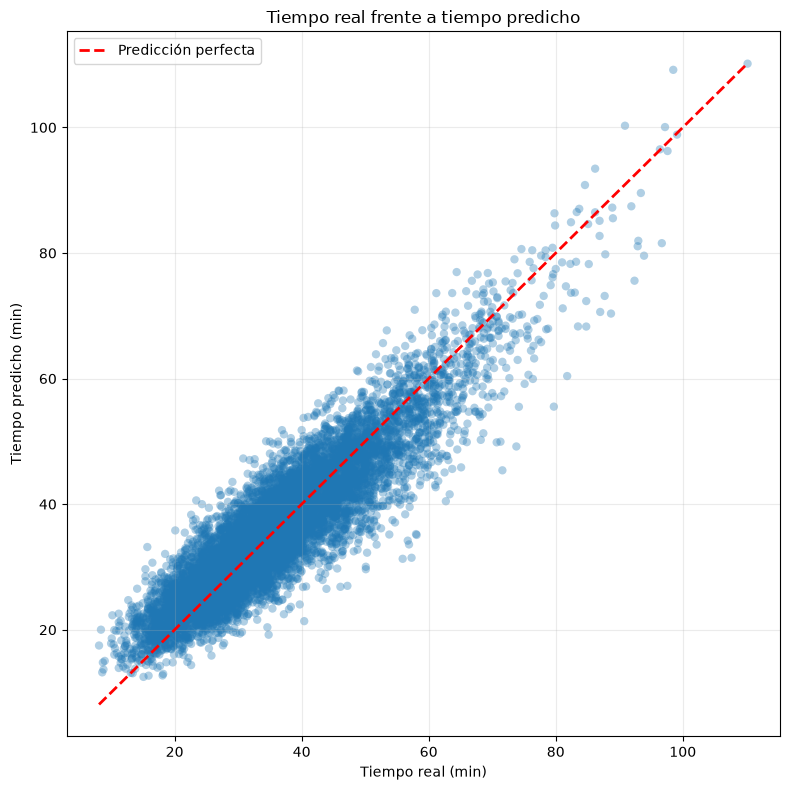


MAE por clima:


,MAE,pedidos
clima,,
lluvia,4.1856 min,"1,750"
tormenta,4.1238 min,395
despejado,4.0959 min,"4,608"
nublado,4.0577 min,"2,619"


MAE por vehículo:


,MAE,pedidos
vehiculo,,
bici,4.1729 min,"3,818"
auto,4.1310 min,"1,105"
moto,4.0364 min,"4,449"


MAE por tramo de distancia:


,MAE,pedidos
tramo_distancia,,
Más de 5 km,4.1173 min,"1,320"
Hasta 2 km,4.1142 min,"3,863"
Más de 2 a 5 km,4.0886 min,"4,189"


In [12]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# La predicción sobre prueba se realiza una sola vez.
mejor_estimador_final = busqueda_ganador.best_estimator_
predicciones_test_final = mejor_estimador_final.predict(X_test)

mae_test_final = mean_absolute_error(y_test, predicciones_test_final)
r2_test_final = r2_score(y_test, predicciones_test_final)
rmse_test_final = mean_squared_error(y_test, predicciones_test_final) ** 0.5
print(f"MAE en prueba: {mae_test_final:.4f} min")
print(f"R² en prueba: {r2_test_final:.4f}")
print(f"RMSE en prueba: {rmse_test_final:.4f} min")

fig, ax = plt.subplots(figsize=(8, 8))
ax.scatter(y_test, predicciones_test_final, alpha=0.35, edgecolors="none")
limite_minimo = min(y_test.min(), predicciones_test_final.min())
limite_maximo = max(y_test.max(), predicciones_test_final.max())
ax.plot([limite_minimo, limite_maximo], [limite_minimo, limite_maximo], "r--", linewidth=2, label="Predicción perfecta")
ax.set_title("Tiempo real frente a tiempo predicho")
ax.set_xlabel("Tiempo real (min)")
ax.set_ylabel("Tiempo predicho (min)")
ax.legend()
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

evaluacion_test = X_test.copy()
evaluacion_test["tiempo_real_min"] = y_test.to_numpy()
evaluacion_test["tiempo_predicho"] = predicciones_test_final
evaluacion_test["error_absoluto"] = (
    evaluacion_test["tiempo_real_min"] - evaluacion_test["tiempo_predicho"]
).abs()

mae_por_clima = (
    evaluacion_test.groupby("clima", observed=False)["error_absoluto"]
    .agg(MAE="mean", pedidos="size")
    .sort_values("MAE", ascending=False)
)
mae_por_vehiculo = (
    evaluacion_test.groupby("vehiculo", observed=False)["error_absoluto"]
    .agg(MAE="mean", pedidos="size")
    .sort_values("MAE", ascending=False)
)
evaluacion_test["tramo_distancia"] = pd.cut(
    evaluacion_test["distancia_km"],
    bins=[-float("inf"), 2, 5, float("inf")],
    labels=["Hasta 2 km", "Más de 2 a 5 km", "Más de 5 km"],
)
mae_por_distancia = (
    evaluacion_test.groupby("tramo_distancia", observed=False)["error_absoluto"]
    .agg(MAE="mean", pedidos="size")
    .sort_values("MAE", ascending=False)
)
print("\nMAE por clima:")
display(mae_por_clima.style.format({"MAE": "{:.4f} min", "pedidos": "{:,.0f}"}))
print("MAE por vehículo:")
display(mae_por_vehiculo.style.format({"MAE": "{:.4f} min", "pedidos": "{:,.0f}"}))
print("MAE por tramo de distancia:")
display(mae_por_distancia.style.format({"MAE": "{:.4f} min", "pedidos": "{:,.0f}"}))

## 8 · El examen final

El mejor estimador de `RandomizedSearchCV` se evaluó una sola vez sobre el conjunto de prueba. El MAE final se compara con el MAE de validación cruzada ajustado (**4,10 min**) y con la línea base (**9,59 min**). Las tablas de desglose muestran en qué condiciones el error absoluto medio es mayor: clima, vehículo y tramo de distancia.

El gráfico compara el tiempo real con el predicho; cuanto más se alejan los puntos de la diagonal, mayor es el error.